# 06 Object catalog and the drag-sensitivity check

First local run of `src/objects.py` (B3) on the 265 cohort objects (250 passive 400-800 km + 15 high-altitude
controls): CelesTrak SATCAT for the object type, ESA DISCOSweb for mass and average cross-section.
Key check for the paper: does our fitted quiet-time drag sensitivity B (from TLEs and MSIS, `src/physics.py`)
rank rocket bodies like the independent catalog value 2.2 x A/m?

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import objects as ob

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
table = pd.read_parquet(ROOT / "data" / "processed" / "analysis_table.parquet")
ids = sorted(table["norad_id"].unique())
# Downloads on the first run (CelesTrak ~2 min, DISCOSweb 3 requests), then reads data/raw/ caches
objs = ob.build_objects(ids)
print(len(ids), "cohort objects ->", objs.shape)

265 cohort objects -> (265, 13)


## 1. Raw replies: do the field names match the code?

In [2]:
discos = json.load(open(ROOT / "data/raw/discos_objects.json"))
satcat = json.load(open(ROOT / "data/raw/satcat_records.json"))
print("DISCOSweb: objects with a reply:", sum(v is not None for v in discos.values()), "of", len(discos))
example = next(k for k, v in discos.items() if v and v.get("mass"))
print("DISCOSweb keys used by objects.py present:", {k: k in discos[example] for k in ["satno", "mass", "xSectAvg"]})
print({k: discos[example][k] for k in ["satno", "name", "objectClass", "mass", "xSectAvg"]})
print("SATCAT keys used:", {k: k in satcat[example] for k in ["OBJECT_NAME", "OBJECT_TYPE", "LAUNCH_DATE", "DECAY_DATE"]})
print(satcat[example])

DISCOSweb: objects with a reply: 265 of 265
DISCOSweb keys used by objects.py present: {'satno': True, 'mass': True, 'xSectAvg': True}
{'satno': 447, 'name': 'Able-Star (Thor-Ablestar)', 'objectClass': 'Rocket Body', 'mass': 445.99, 'xSectAvg': 6.047565858160351}
SATCAT keys used: {'OBJECT_NAME': True, 'OBJECT_TYPE': True, 'LAUNCH_DATE': True, 'DECAY_DATE': True}
{'OBJECT_NAME': 'THOR ABLESTAR R/B', 'OBJECT_ID': '1962-060B', 'NORAD_CAT_ID': 447, 'OBJECT_TYPE': 'R/B', 'OPS_STATUS_CODE': '', 'OWNER': 'US', 'LAUNCH_DATE': '1962-10-31', 'LAUNCH_SITE': 'AFETR', 'DECAY_DATE': '', 'PERIOD': 107.53, 'INCLINATION': 50.13, 'APOGEE': 1162, 'PERIGEE': 1063, 'RCS': 3.3285, 'DATA_STATUS_CODE': '', 'ORBIT_CENTER': 'EA', 'ORBIT_TYPE': 'ORB'}


## 2. Coverage and activity

In [3]:
objs["has_a_m"] = objs["area_to_mass"].notna()
print(pd.crosstab(objs["object_type"], objs["has_a_m"], margins=True).rename(columns={False: "no A/m", True: "has A/m"}))
print("A/m (m^2/kg) of objects that have it:")
print(objs["area_to_mass"].describe().round(4))
print("payloads in cohort:", (objs["object_type"] == "payload").sum(),
      "| payloads searched by detect_maneuvers:", objs["maneuver_checked"].sum(),
      "| flagged active:", objs["is_active"].sum())

has_a_m      no A/m  has A/m  All
object_type                      
debris          147        2  149
rocket body       0      116  116
All             147      118  265
A/m (m^2/kg) of objects that have it:
count    118.0000
mean       0.0093
std        0.0064
min        0.0029
25%        0.0053
50%        0.0073
75%        0.0103
max        0.0465
Name: area_to_mass, dtype: float64
payloads in cohort: 0 | payloads searched by detect_maneuvers: 0 | flagged active: 0


The cohort is passive-only by construction (debris and rocket bodies), so it contains **no payloads** and the maneuver search
had nothing to run on: 0 payloads flagged active. `detect_maneuvers` is only exercised by the unit tests until the
active-satellite cohort for question 3 is selected.

## 3. Fitted vs catalog drag sensitivity

Rocket bodies: Spearman rho = 0.812, p = 2.0e-28, n = 116
Main group only (400-800 km): rho = 0.818, n = 109


Debris: n with both values = 2 (too few for a correlation)


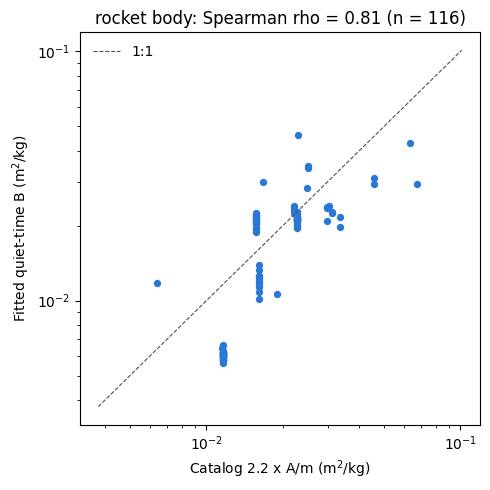

In [4]:
fit = table.groupby("norad_id").agg(drag_sensitivity=("drag_sensitivity", "first"),
                                    group=("cohort_group", "first"),
                                    alt=("alt_km", "median")).reset_index()
res, fig = ob.compare_drag(fit, objs, out_path=RESULTS / "objects_drag_compare.png")
print(f"Rocket bodies: Spearman rho = {res['rho']:.3f}, p = {res['p_value']:.1e}, n = {res['n']}")
main_only, _ = ob.compare_drag(fit[fit["group"] == "main"], objs)
plt.close("all")
print(f"Main group only (400-800 km): rho = {main_only['rho']:.3f}, n = {main_only['n']}")
deb, _ = ob.compare_drag(fit, objs, object_type="debris")
plt.close("all")
print("Debris: n with both values =", deb["n"], "(too few for a correlation)")
fig

fitted / catalog B, rocket bodies:
count    116.00
mean       0.86
std        0.34
min        0.43
25%        0.53
50%        0.79
75%        1.00
max        2.02
Name: ratio, dtype: float64
log10 ratio sd: 0.165
Spearman(log ratio, altitude): 0.56


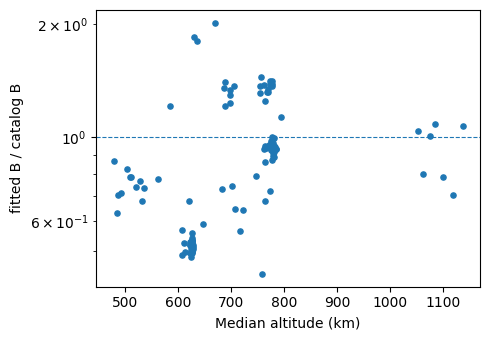

In [5]:
x = res["table"].merge(fit[["norad_id", "alt"]], on="norad_id")
x["ratio"] = x["drag_sensitivity"] / x["drag_sensitivity_catalog"]
print("fitted / catalog B, rocket bodies:")
print(x["ratio"].describe().round(2))
print("log10 ratio sd:", round(np.log10(x["ratio"]).std(), 3))
print("Spearman(log ratio, altitude):", round(x[["ratio", "alt"]].corr(method="spearman").iloc[0, 1], 2))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x["alt"], x["ratio"], s=14)
ax.axhline(1, ls="--", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("Median altitude (km)")
ax.set_ylabel("fitted B / catalog B")
fig.tight_layout()
fig.savefig(RESULTS / "objects_drag_ratio_vs_alt.png", dpi=150)

## 4. Reading

- The ordering agrees strongly (rho about 0.81), so the quiet-time fit picks up real object drag properties, not noise.
- The fit sits below the 2.2 x A/m line for most objects (median ratio about 0.8) and the ratio grows with altitude.
  A catalog cross-section is an orientation average and Cd = 2.2 is a convention, so a level offset is expected;
  only the ranking is used as validation.